**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
%pip -q install prophet tensorflow statsmodels scikit-learn
import os, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
warnings.filterwarnings('ignore', category=FutureWarning)
np.random.seed(42); random.seed(42); tf.random.set_seed(42)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize']=(13,5)
print('Бібліотеки імпортовано. TensorFlow:', tf.__version__)

Бібліотеки імпортовано. TensorFlow: 2.21.0


In [2]:
# У Colab завантажте доданий до роботи CSV; у локальному Jupyter файл можна тримати поруч.
from pathlib import Path
candidates = [Path('/content/kaggel_weather_2013_to_2024(1).csv'),
              Path('/content/kaggel_weather_2013_to_2024.csv'),
              Path('kaggel_weather_2013_to_2024(1).csv'),
              Path('kaggel_weather_2013_to_2024.csv')]
csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    from google.colab import files
    print('Оберіть файл kaggel_weather_2013_to_2024(1).csv')
    uploaded = files.upload()
    csv_path = Path(next((k for k in uploaded if k.lower().endswith('.csv')), ''))
    if not csv_path.is_file(): raise FileNotFoundError('Потрібно завантажити CSV із кліматичними даними.')
print('Файл даних:', csv_path)

Оберіть файл kaggel_weather_2013_to_2024(1).csv


Saving kaggel_weather_2013_to_2024.csv to kaggel_weather_2013_to_2024.csv
Файл даних: kaggel_weather_2013_to_2024.csv


In [3]:
raw = pd.read_csv(csv_path)
print('Розмір:',raw.shape)
display(raw.head())
display(raw.describe(include='all').T)

Розмір: (3557, 29)


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,3557.0,NaN,NaN,NaN,1778.0,1026.961781,0.0,889.0,1778.0,2667.0,3556.0
DATE,3557,3556,5/1/2022,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tempmax,3557.0,NaN,NaN,NaN,31.367501,7.073934,9.1,26.4,33.0,36.0,47.9
tempmin,3557.0,NaN,NaN,NaN,20.076132,7.568531,2.0,13.0,22.0,26.9,34.8
temp,3557.0,NaN,NaN,NaN,25.403374,7.325541,6.5,19.1,27.7,31.0,39.5
feelslikemax,3557.0,NaN,NaN,NaN,34.28018,9.651743,7.9,26.3,35.4,42.7,57.7
feelslikemin,3557.0,NaN,NaN,NaN,20.938769,9.004827,0.3,13.0,22.0,28.0,41.1
feelslike,3557.0,NaN,NaN,NaN,27.306803,9.301636,5.7,19.1,28.4,35.4,47.0
humidity,3557.0,NaN,NaN,NaN,63.75544,18.129251,16.1,53.0,65.8,76.9,99.3
precip,3557.0,NaN,NaN,NaN,2.459033,10.636255,0.0,0.0,0.0,0.0,203.047


Підготовка даних

In [4]:
df = raw.copy()
df['DATE'] = pd.to_datetime(df['DATE'], errors='coerce')
df['temp'] = pd.to_numeric(df['temp'], errors='coerce')
df = df.dropna(subset=['DATE']).sort_values('DATE').drop_duplicates(subset='DATE',keep='last')
df = df.drop(columns=[c for c in df.columns if c.startswith('Unnamed:')], errors='ignore')
df = df.set_index('DATE')
# Усі календарні дні, щоб часовий ряд мав рівномірну частоту.
df = df.asfreq('D')
print('Період:',df.index.min().date(), '—',df.index.max().date())
print('Пропуски temp до заповнення:',df['temp'].isna().sum())
df['temp'] = df['temp'].interpolate(method='time',limit_direction='both')
display(df.head())

Період: 2013-04-14 — 2024-11-30
Пропуски temp до заповнення: 693


,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100.0,4.17,...,13.0,15.0,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0.0,0.00,...,13.0,16.0,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0.0,0.00,...,13.0,16.0,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0.0,0.00,...,13.0,16.0,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0.0,0.00,...,13.0,16.0,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [5]:
df.info()
print('Статистика температури:')
display(df['temp'].describe().to_frame())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4249 entries, 2013-04-14 to 2024-11-30
Freq: D
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3556 non-null   float64
 1   tempmin                3556 non-null   float64
 2   temp                   4249 non-null   float64
 3   feelslikemax           3556 non-null   float64
 4   feelslikemin           3556 non-null   float64
 5   feelslike              3556 non-null   float64
 6   humidity               3556 non-null   float64
 7   precip                 3556 non-null   float64
 8   precipprob             3556 non-null   float64
 9   precipcover            3556 non-null   float64
 10  windspeed              3556 non-null   float64
 11  sealevelpressure       3556 non-null   float64
 12  conditions             3556 non-null   object 
 13  Year                   3556 non-null   float64
 14  month                  3556 no

,temp
count,4249.000000
mean,25.431466
std,7.228744
min,6.500000
25%,19.100000
50%,27.853846
75%,31.007692
max,39.500000


In [6]:
print('Пропущені значення за стовпцями (інші показники не використовуються у моделях):')
display(df.isna().sum().sort_values(ascending=False).to_frame('Кількість пропусків'))
assert df['temp'].notna().all(), 'У температурному ряді залишилися пропуски'

Пропущені значення за стовпцями (інші показники не використовуються у моделях):


,Кількість пропусків
tempmax,693
tempmin,693
feelslikemax,693
precip,693
feelslikemin,693
feelslike,693
humidity,693
precipcover,693
precipprob,693
windspeed,693


Графік температури

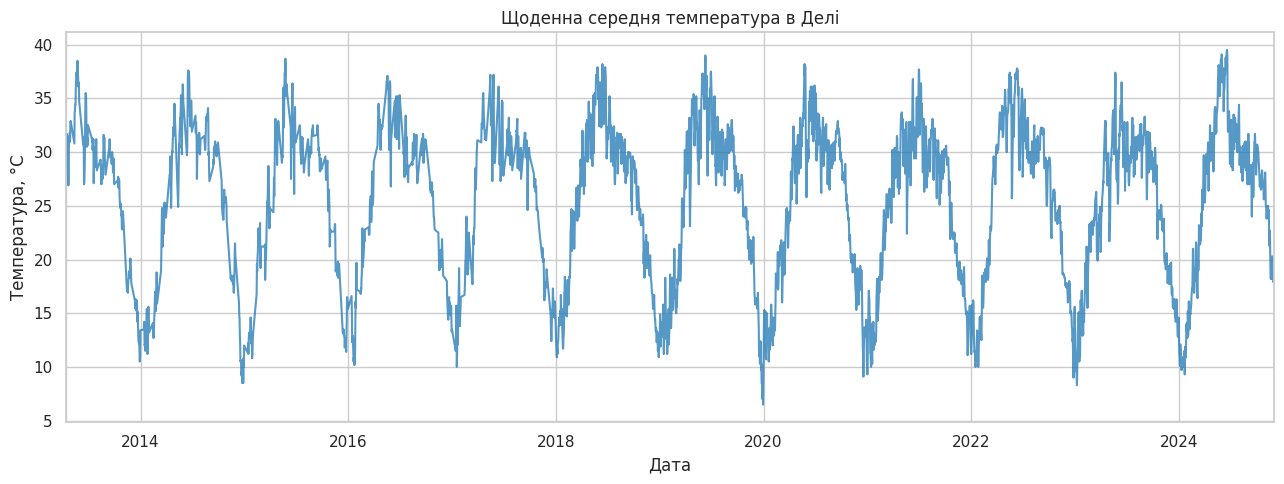

In [7]:
ax=df['temp'].plot(color='tab:blue',alpha=.75,title='Щоденна середня температура в Делі')
ax.set(xlabel='Дата',ylabel='Температура, °C');plt.tight_layout();plt.show()

Ковзне середнє

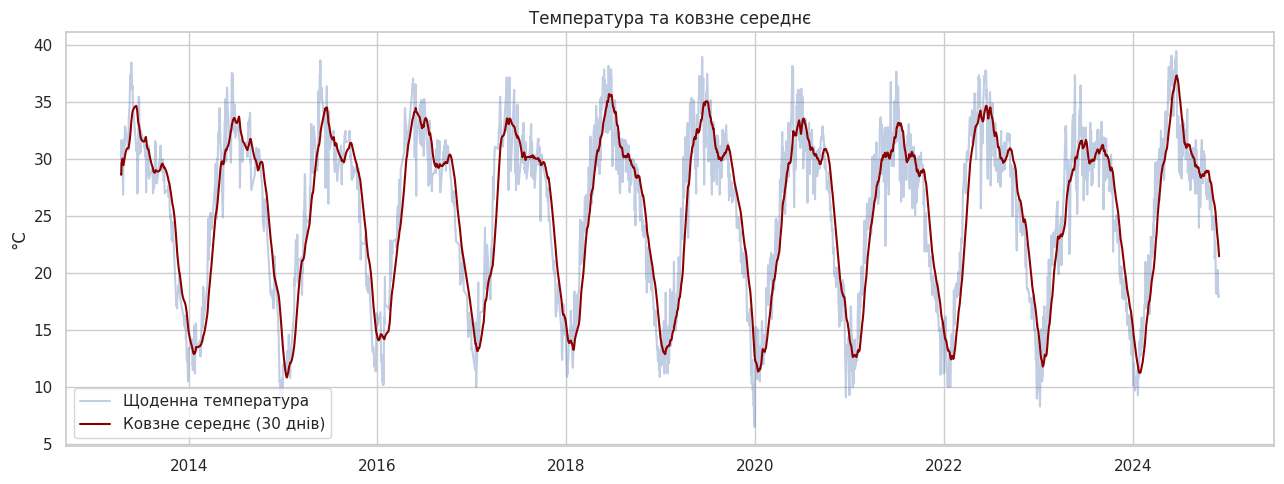

In [8]:
ma30=df['temp'].rolling(30,min_periods=1).mean()
plt.plot(df.index,df['temp'],alpha=.35,label='Щоденна температура')
plt.plot(ma30.index,ma30,color='darkred',label='Ковзне середнє (30 днів)')
plt.title('Температура та ковзне середнє');plt.ylabel('°C');plt.legend();plt.tight_layout();plt.show()

Розподіл температури

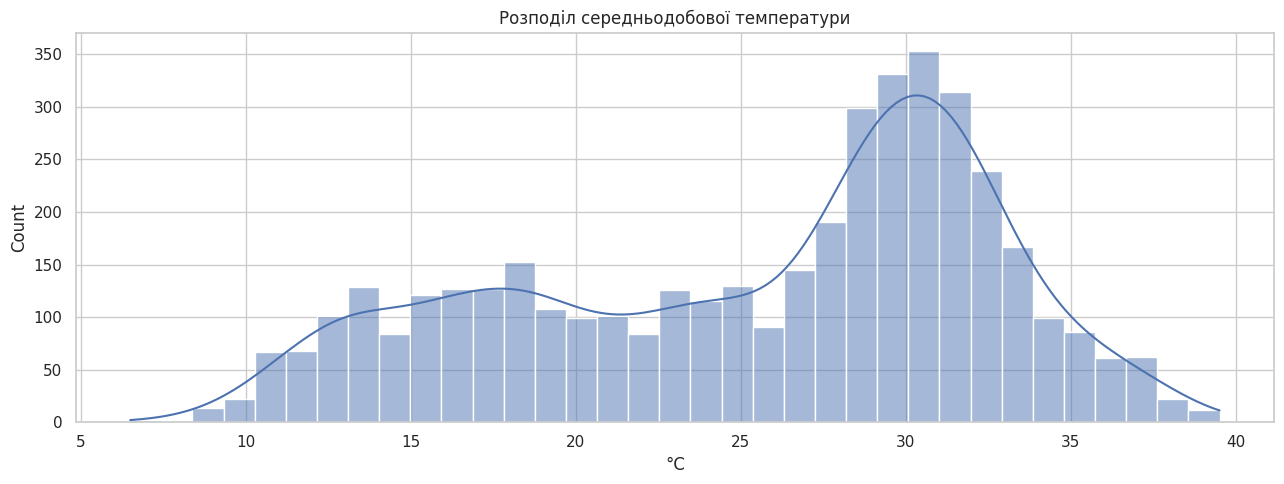

In [9]:
sns.histplot(df['temp'],bins=35,kde=True)
plt.title('Розподіл середньодобової температури');plt.xlabel('°C');plt.tight_layout();plt.show()

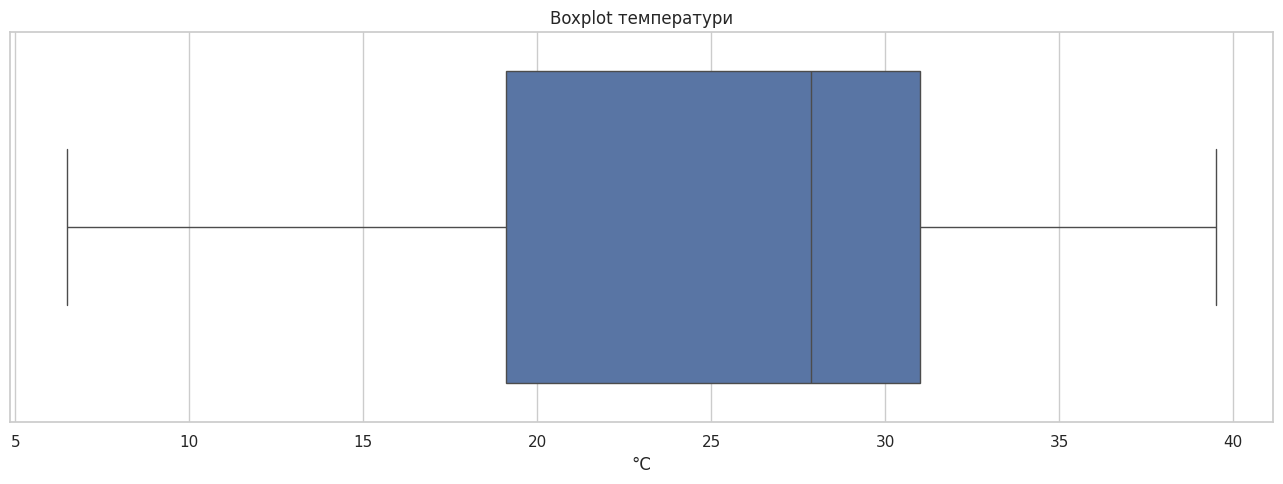

Потенційні викиди за правилом 1.5×IQR: 0


In [10]:
sns.boxplot(x=df['temp']);plt.title('Boxplot температури');plt.xlabel('°C');plt.tight_layout();plt.show()
q1,q3=df['temp'].quantile([.25,.75]);iqr=q3-q1
print('Потенційні викиди за правилом 1.5×IQR:',int(((df['temp']<q1-1.5*iqr)|(df['temp']>q3+1.5*iqr)).sum()))

Аналіз автокореляції
ACF

PACF

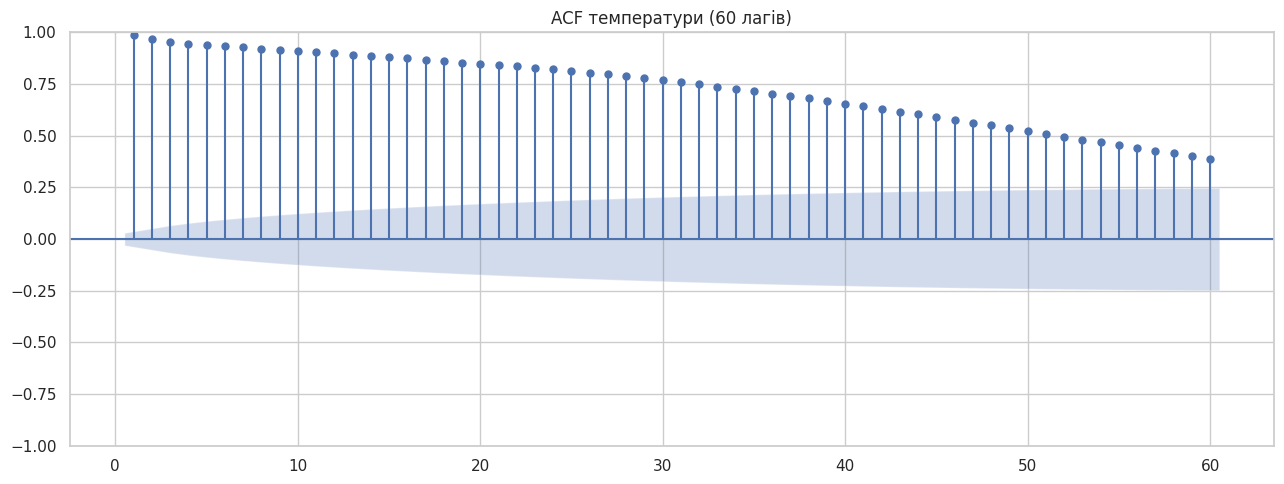

In [11]:
plot_acf(df['temp'],lags=60,zero=False);plt.title('ACF температури (60 лагів)');plt.tight_layout();plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

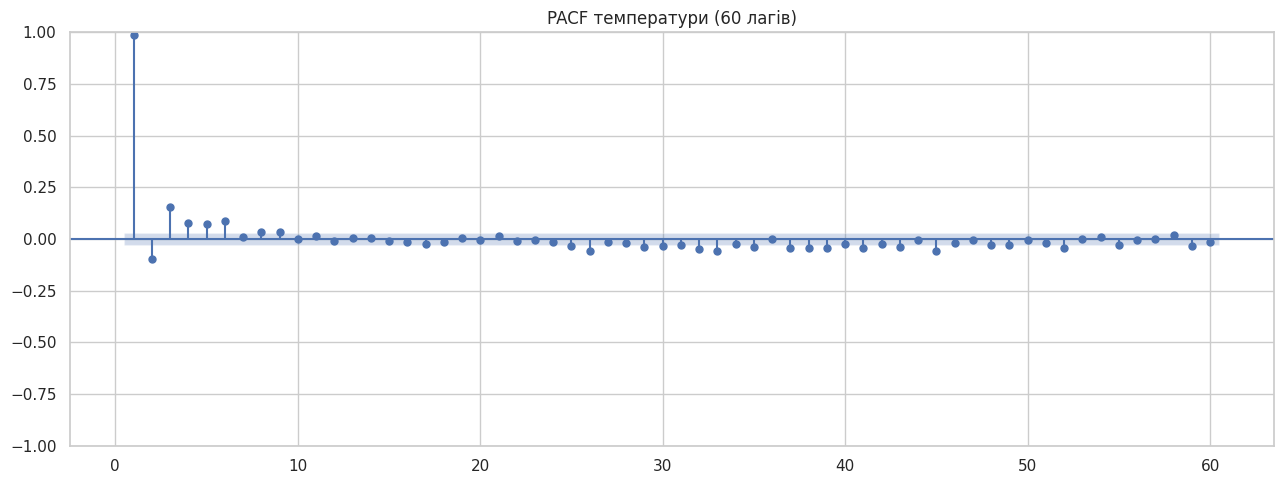

ADF статистика: -4.9996; p-value: 2.224e-05
Ряд стаціонарний за ADF (5%)


In [12]:
plot_pacf(df['temp'],lags=60,method='ywm',zero=False);plt.title('PACF температури (60 лагів)');plt.tight_layout();plt.show()
adf=adfuller(df['temp'].dropna(),autolag='AIC')
print(f'ADF статистика: {adf[0]:.4f}; p-value: {adf[1]:.4g}')
print('Ряд стаціонарний за ADF (5%)' if adf[1]<.05 else 'Немає підстав вважати ряд стаціонарним за ADF (5%)')

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [13]:
series=df['temp'].astype('float32').copy()
# Останні 20% дат — тест; жодного перемішування чи витоку майбутніх даних.
split=int(len(series)*.8)
train=series.iloc[:split];test=series.iloc[split:]
print('Train:',len(train),train.index.min().date(),train.index.max().date())
print('Test:',len(test),test.index.min().date(),test.index.max().date())
assert train.index.max()<test.index.min()

Train: 3399 2013-04-14 2022-08-03
Test: 850 2022-08-04 2024-11-30


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [14]:
# ARIMA(5,1,2): авторегресія + перше диференціювання + ковзна середня.
# Прогноз на весь тестовий горизонт без використання фактичних тестових значень.
arima_model=ARIMA(train.astype(float),order=(5,1,2),enforce_stationarity=False,enforce_invertibility=False)
arima_fit=arima_model.fit()
arima_pred=pd.Series(np.asarray(arima_fit.forecast(steps=len(test))),index=test.index,name='ARIMA')
print('ARIMA навчена; прогнозних точок:',len(arima_pred))

ARIMA навчена; прогнозних точок: 850


In [15]:
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 3399
Model:                 ARIMA(5, 1, 2)   Log Likelihood               -5395.102
Date:                Wed, 04 Nov 2026   AIC                          10806.204
Time:                        14:13:12   BIC                          10855.240
Sample:                    04-14-2013   HQIC                         10823.732
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2764      0.277      0.998      0.318      -0.266       0.819
ar.L2          0.1031      0.249      0.414      0.679      -0.385       0.592
ar.L3         -0.0923      0.069     -1.346      0.1

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

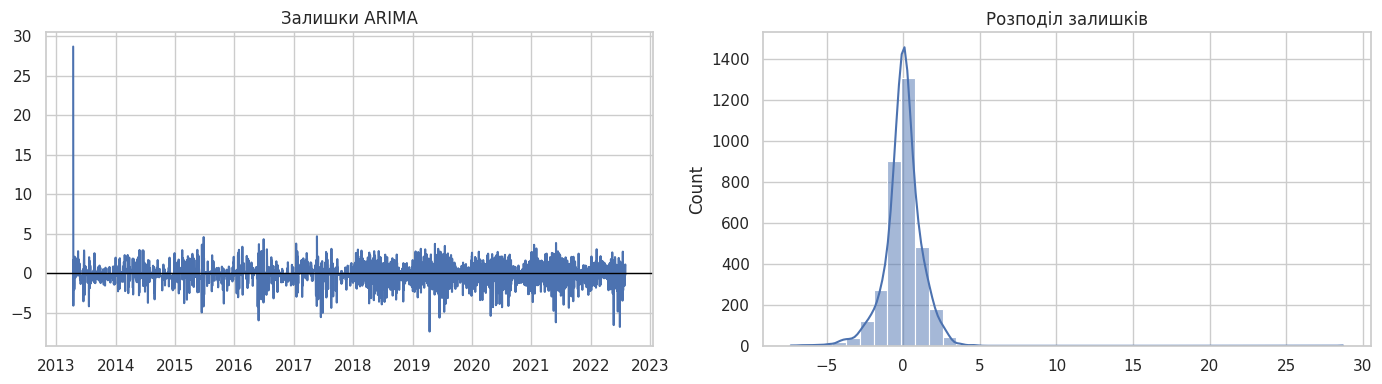

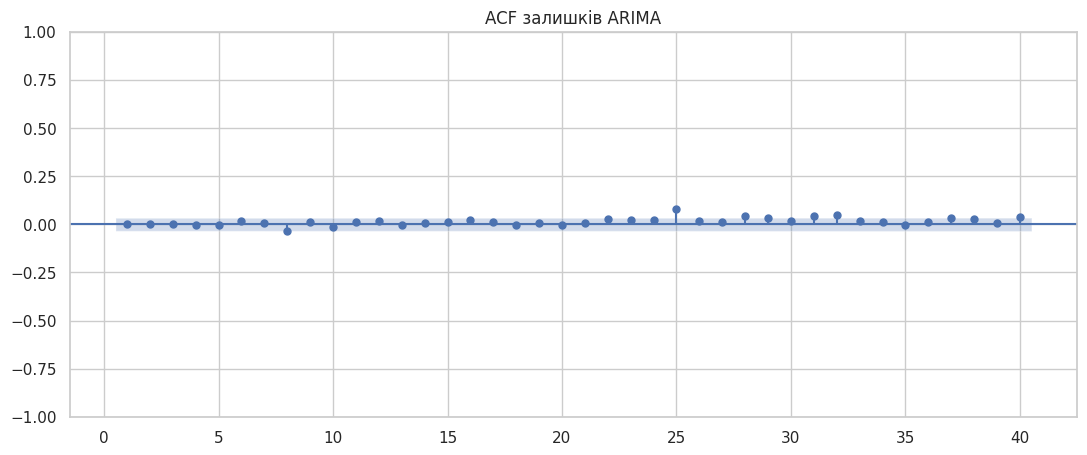

In [16]:
residuals=pd.Series(arima_fit.resid).dropna()
fig,axes=plt.subplots(1,2,figsize=(14,4))
axes[0].plot(residuals.index,residuals);axes[0].axhline(0,color='black',lw=1);axes[0].set_title('Залишки ARIMA')
sns.histplot(residuals,bins=40,kde=True,ax=axes[1]);axes[1].set_title('Розподіл залишків')
plt.tight_layout();plt.show()
plot_acf(residuals.iloc[10:],lags=40,zero=False);plt.title('ACF залишків ARIMA');plt.show()

In [17]:
def mape(y_true,y_pred):
    a=np.asarray(y_true,dtype=float);b=np.asarray(y_pred,dtype=float)
    mask=np.abs(a)>1e-8
    return float(np.mean(np.abs((a[mask]-b[mask])/a[mask]))*100) if mask.any() else np.nan

def metrics(y_true,y_pred):
    return {'MAE (°C)':mean_absolute_error(y_true,y_pred),
            'RMSE (°C)':np.sqrt(mean_squared_error(y_true,y_pred)),
            'MAPE (%)':mape(y_true,y_pred)}
arima_metrics=metrics(test,arima_pred)
print('ARIMA:',{k:round(v,3) for k,v in arima_metrics.items()})

ARIMA: {'MAE (°C)': 6.196, 'RMSE (°C)': np.float64(8.404), 'MAPE (%)': 35.793}


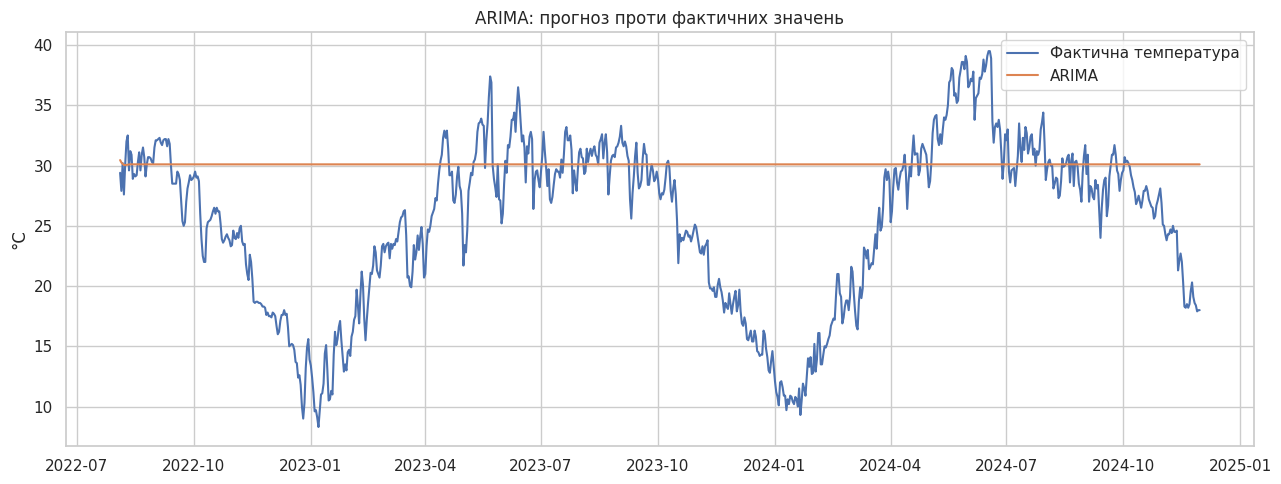

In [18]:
plt.plot(test.index,test,label='Фактична температура',lw=1.5)
plt.plot(arima_pred.index,arima_pred,label='ARIMA',lw=1.5)
plt.title('ARIMA: прогноз проти фактичних значень');plt.ylabel('°C');plt.legend();plt.tight_layout();plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [19]:
prophet_train=train.rename('y').reset_index().rename(columns={'DATE':'ds'})
prophet_test=test.rename('y').reset_index().rename(columns={'DATE':'ds'})
assert {'ds','y'}.issubset(prophet_train.columns)
display(prophet_train.head())

,ds,y
0,2013-04-14,28.700001
1,2013-04-15,28.600000
2,2013-04-16,31.700001
3,2013-04-17,29.900000
4,2013-04-18,30.600000


In [20]:
# Річна сезонність важлива для температури; денна та тижнева не потрібні.
prophet_model=Prophet(yearly_seasonality=True,weekly_seasonality=False,daily_seasonality=False,
                      seasonality_mode='additive',changepoint_prior_scale=.05)
prophet_model.fit(prophet_train)
print('Prophet навчено')

Prophet навчено


Прогноз

In [21]:
future=prophet_test[['ds']].copy()
prophet_forecast=prophet_model.predict(future)
prophet_pred=pd.Series(prophet_forecast['yhat'].to_numpy(),index=test.index,name='Prophet')
display(prophet_forecast[['ds','yhat','yhat_lower','yhat_upper']].head())

,ds,yhat,yhat_lower,yhat_upper
0,2022-08-04,30.428858,27.841067,32.956220
1,2022-08-05,30.500378,28.181350,33.148159
2,2022-08-06,30.576375,28.011200,33.101657
3,2022-08-07,30.654511,28.123791,33.091183
4,2022-08-08,30.732471,28.136692,33.305102


In [22]:
prophet_metrics=metrics(test,prophet_pred)
print('Prophet:',{k:round(v,3) for k,v in prophet_metrics.items()})

Prophet: {'MAE (°C)': 2.069, 'RMSE (°C)': np.float64(2.648), 'MAPE (%)': 9.349}


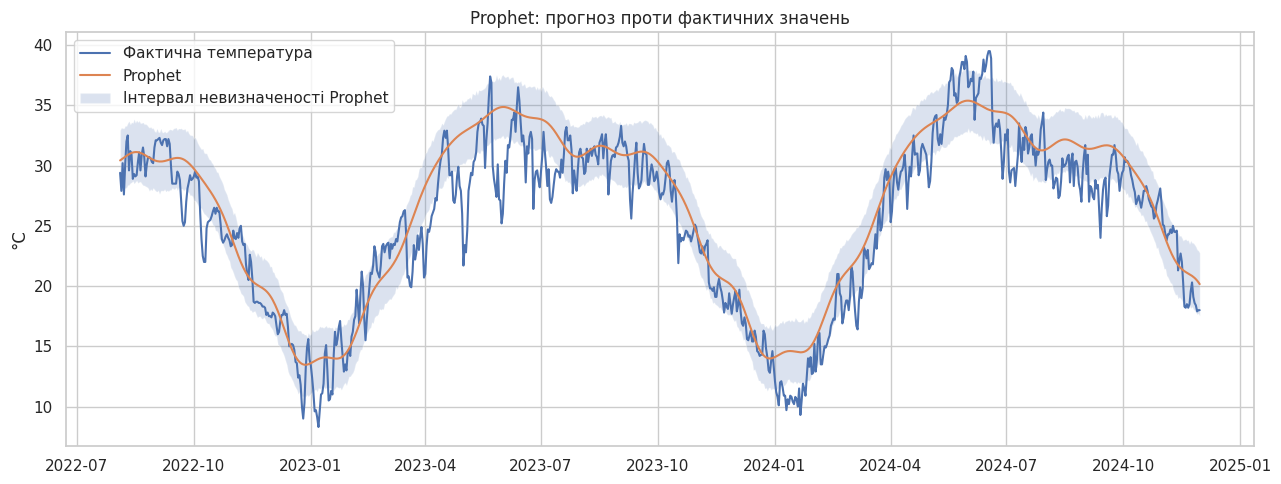

In [23]:
plt.plot(test.index,test,label='Фактична температура')
plt.plot(test.index,prophet_pred,label='Prophet')
plt.fill_between(test.index,prophet_forecast['yhat_lower'].to_numpy(),prophet_forecast['yhat_upper'].to_numpy(),alpha=.2,label='Інтервал невизначеності Prophet')
plt.title('Prophet: прогноз проти фактичних значень');plt.ylabel('°C');plt.legend();plt.tight_layout();plt.show()

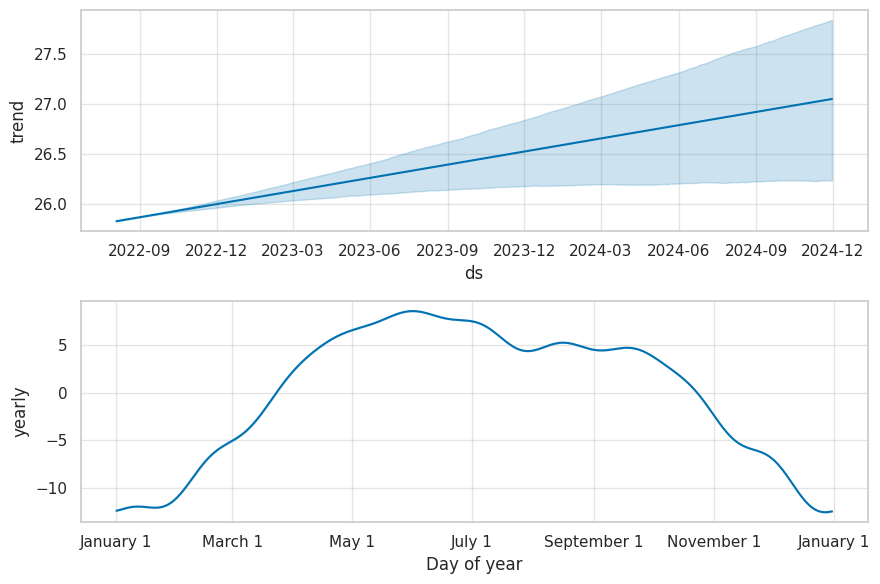

In [24]:
prophet_model.plot_components(prophet_forecast);plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [25]:
# Масштабувальник навчається ТІЛЬКИ на train (без витоку інформації).
scaler=MinMaxScaler()
scaled_train=scaler.fit_transform(train.to_numpy().reshape(-1,1)).ravel()
scaled_all=scaler.transform(series.to_numpy().reshape(-1,1)).ravel()
lookback=30

def make_windows(values, start_target, stop_target, window):
    X=np.array([values[i-window:i] for i in range(start_target,stop_target)],dtype=np.float32)
    y=np.array([values[i] for i in range(start_target,stop_target)],dtype=np.float32)
    return X[...,None],y
X_train,y_train=make_windows(scaled_all,lookback,split,lookback)
# Вікна test формуються тільки з train та попередніх test-спостережень.
# Це one-step-ahead оцінка з відомою історією; не тотожна багатокроковому прогнозу ARIMA/Prophet.
X_test,y_test=make_windows(scaled_all,split,len(series),lookback)
print('X_train:',X_train.shape,'X_test:',X_test.shape)

X_train: (3369, 30, 1) X_test: (850, 30, 1)


In [26]:
print('Навчальні мітки:',len(y_train),'Тестові мітки:',len(y_test))
assert len(X_test)==len(test) and len(X_train)==len(train)-lookback
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()

Навчальні мітки: 3369 Тестові мітки: 850


In [27]:
tf.keras.backend.clear_session()
lstm_model=Sequential([Input(shape=(lookback,1)),LSTM(48),Dropout(.15),Dense(16,activation='relu'),Dense(1)])
lstm_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001),loss='mse',metrics=['mae'])
print('LSTM скомпільована')

LSTM скомпільована


Epoch 1/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - loss: 0.0653 - mae: 0.1641 - val_loss: 0.0063 - val_mae: 0.0647
Epoch 2/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0073 - mae: 0.0674 - val_loss: 0.0057 - val_mae: 0.0601
Epoch 3/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0060 - mae: 0.0604 - val_loss: 0.0062 - val_mae: 0.0636
Epoch 4/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0057 - mae: 0.0579 - val_loss: 0.0052 - val_mae: 0.0571
Epoch 5/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0050 - mae: 0.0543 - val_loss: 0.0043 - val_mae: 0.0511
Epoch 6/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0048 - mae: 0.0539 - val_loss: 0.0050 - val_mae: 0.0563
Epoch 7/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0042 - mae: 0.0507 - val_loss: 0.0043 - val_mae: 0.0510
Epoch 8/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0042 - mae: 0.0501 - val_loss: 0.0040 - val_mae: 0.0491
Epoch 9/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0039 - mae

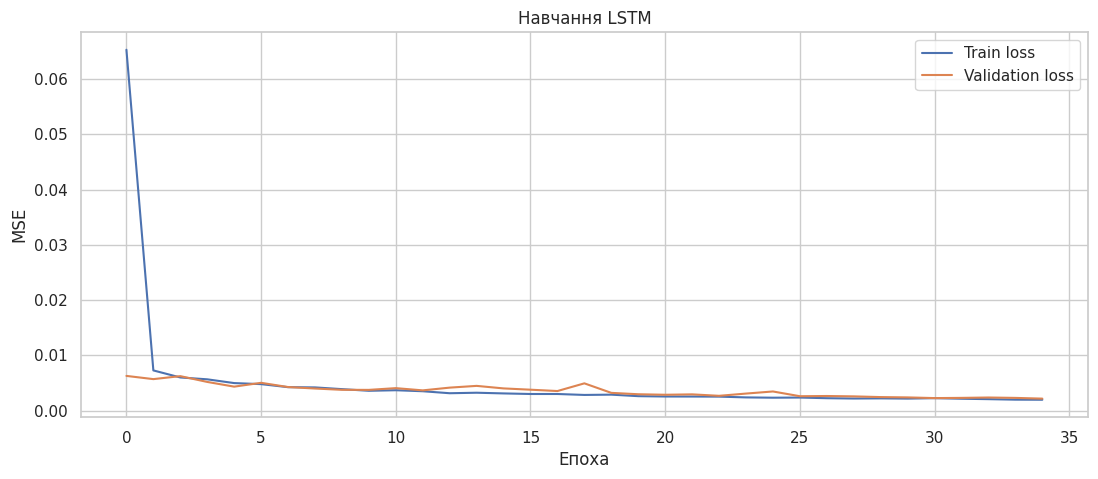

In [28]:
history=lstm_model.fit(X_train,y_train,epochs=35,batch_size=32,validation_split=.15,
                       shuffle=False,callbacks=[EarlyStopping(monitor='val_loss',patience=6,restore_best_weights=True)],verbose=1)
plt.plot(history.history['loss'],label='Train loss');plt.plot(history.history['val_loss'],label='Validation loss')
plt.title('Навчання LSTM');plt.xlabel('Епоха');plt.ylabel('MSE');plt.legend();plt.show()

In [29]:
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 48)             │         9,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,205 (121.90 KB)

 Trainable params: 10,401 (40.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 20,804 (81.27 KB)

In [30]:
lstm_scaled=lstm_model.predict(X_test,verbose=0)
lstm_values=scaler.inverse_transform(lstm_scaled).ravel()
print('Кількість прогнозів LSTM:',len(lstm_values))

Кількість прогнозів LSTM: 850


In [31]:
lstm_pred=pd.Series(lstm_values,index=test.index,name='LSTM (1 крок)')
display(lstm_pred.head())

,LSTM (1 крок)
DATE,
2022-08-04,30.322367
2022-08-05,29.143232
2022-08-06,27.685812
2022-08-07,29.264889
2022-08-08,27.590118


In [32]:
lstm_metrics=metrics(test,lstm_pred)
print('LSTM:',{k:round(v,3) for k,v in lstm_metrics.items()})

LSTM: {'MAE (°C)': 1.041, 'RMSE (°C)': np.float64(1.336), 'MAPE (%)': 4.427}


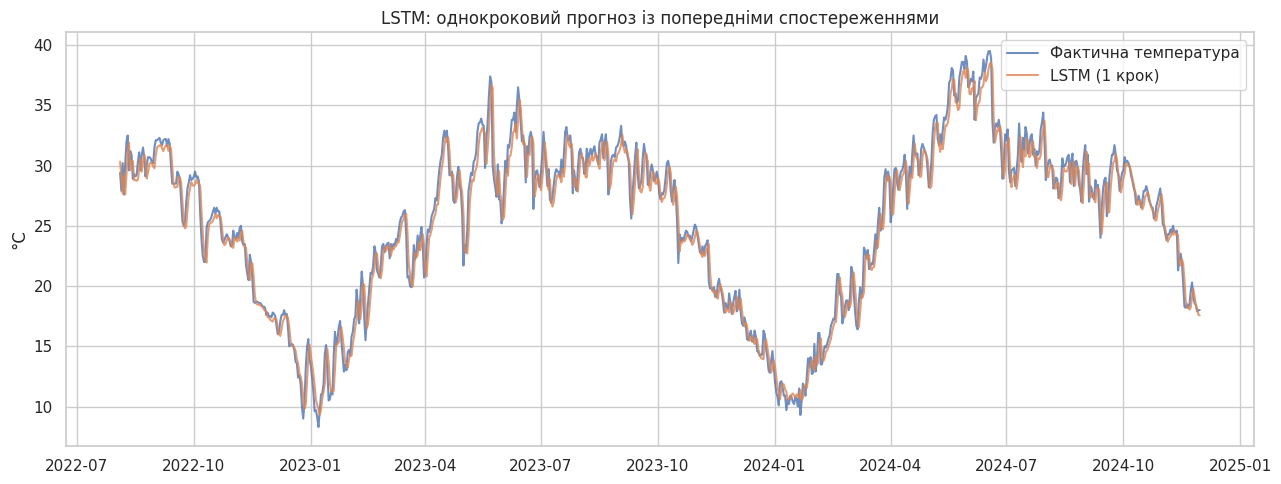

In [33]:
plt.plot(test.index,test,label='Фактична температура',alpha=.8)
plt.plot(lstm_pred.index,lstm_pred,label='LSTM (1 крок)',alpha=.8)
plt.title('LSTM: однокроковий прогноз із попередніми спостереженнями');plt.ylabel('°C');plt.legend();plt.tight_layout();plt.show()

Порівняння моделей

,MAE (°C),RMSE (°C),MAPE (%)
LSTM (1 крок),1.041,1.336,4.427
Prophet,2.069,2.648,9.349
ARIMA,6.196,8.404,35.793


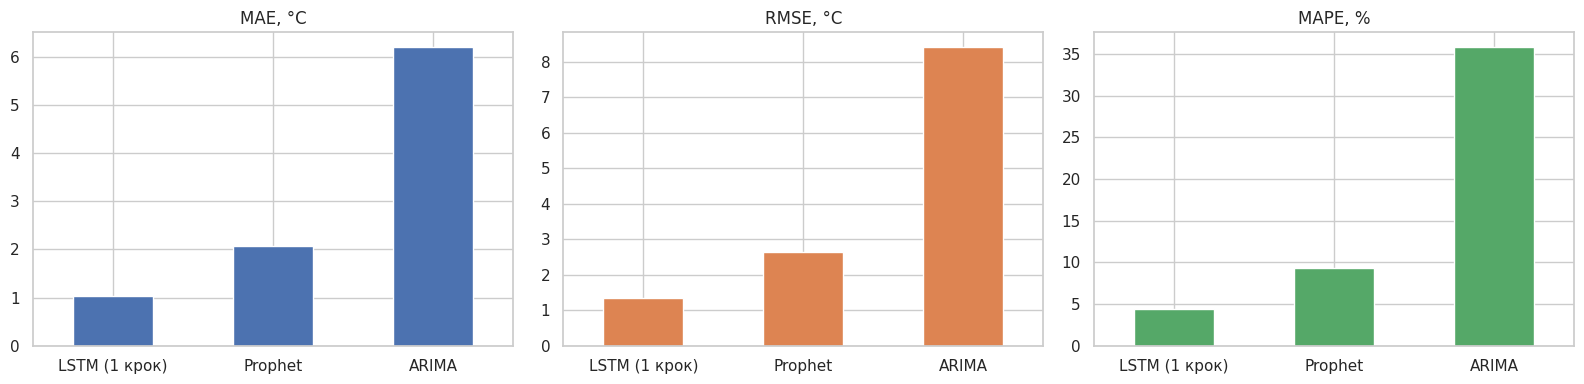

Найнижча RMSE: LSTM (1 крок)
ВАЖЛИВО: ARIMA/Prophet прогнозують увесь горизонт без тестових значень,
а LSTM використовує попередні фактичні значення тестового періоду.
Тому їхні метрики відображають різні режими прогнозування і не є повністю зіставними.


In [34]:
comparison=pd.DataFrame({'ARIMA':arima_metrics,'Prophet':prophet_metrics,'LSTM (1 крок)':lstm_metrics}).T
comparison=comparison.sort_values('RMSE (°C)')
display(comparison.round(3))
comparison.plot(kind='bar',subplots=True,layout=(1,3),figsize=(16,4),legend=False,rot=0,
                title=['MAE, °C','RMSE, °C','MAPE, %']);plt.tight_layout();plt.show()
winner=comparison.index[0]
print('Найнижча RMSE:',winner)
print('ВАЖЛИВО: ARIMA/Prophet прогнозують увесь горизонт без тестових значень,')
print('а LSTM використовує попередні фактичні значення тестового періоду.')
print('Тому їхні метрики відображають різні режими прогнозування і не є повністю зіставними.')

## Висновок

У роботі виконано підготовку щоденних кліматичних даних Делі: перетворено дату, впорядковано часовий ряд, перевірено пропуски та досліджено температуру за допомогою графіка, ковзного середнього, гістограми, boxplot, ACF і PACF. Побудовано ARIMA(5,1,2), Prophet з річною сезонністю та LSTM з вікном 30 днів. Для оцінювання використано MAE, RMSE і MAPE.

**Підсумкові числові значення й найкраща модель визначаються автоматично після запуску всіх комірок.** Важливе методичне обмеження: ARIMA і Prophet виконують багатокроковий прогноз без тестових спостережень, а LSTM — однокроковий прогноз із використанням попередніх фактичних значень. Отже, пряме ранжування цих трьох режимів потребує обережності. Нижче формується висновок за реально обчисленими метриками.

In [35]:
print('ВИСНОВКИ ЗА РЕЗУЛЬТАТАМИ ОБЧИСЛЕНЬ')
for name,row in comparison.iterrows():
    print(f"{name}: MAE = {row['MAE (°C)']:.3f} °C, RMSE = {row['RMSE (°C)']:.3f} °C, MAPE = {row['MAPE (%)']:.2f}%")
print(f'Мінімальну RMSE у проведеному експерименті має {winner}.')
print('Для остаточного чесного порівняння слід оцінити всі моделі в однаковому режимі прогнозування.')

ВИСНОВКИ ЗА РЕЗУЛЬТАТАМИ ОБЧИСЛЕНЬ
LSTM (1 крок): MAE = 1.041 °C, RMSE = 1.336 °C, MAPE = 4.43%
Prophet: MAE = 2.069 °C, RMSE = 2.648 °C, MAPE = 9.35%
ARIMA: MAE = 6.196 °C, RMSE = 8.404 °C, MAPE = 35.79%
Мінімальну RMSE у проведеному експерименті має LSTM (1 крок).
Для остаточного чесного порівняння слід оцінити всі моделі в однаковому режимі прогнозування.
